# Мои домашние работы по Теории Вероятности

## Библиотеки

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.stats import norm

## Задание 1

### Условие

Создайте свой кодовый блокнот, назовите его латиницей "`ProbT_[ваша фамилия]" и напиши строчку кода, которая выводит "hello world"

### Решение

In [ ]:
print("hello world")

hello world


## Задание 2

### Условие

Напишите алгоритм, который вычисляет значение числа пи с помощью генератора псевдослучайной последовательности и строит график зависимости точности вычисления этого числа от шага вычисления.

### Решение

Как я понял задание - нужно визуализировать метод Монте-Карло. Можно поступить следующим образом:

1. Очертить окружность радиусом 1, заключённую в квадрат стороной 2
2. Случайно сгенерировать набор точек внутри квадрата и отметить количество точек, которые при этом попали в окружность
3. По методу Монте-Карло, отношение площади окружности к площади квадрата, будет приблизительно равняться отношению количества точек внутри окружности к количеству всех точек. В виде формулы это будет:

$$
\frac{S_{окр}}{S_{квд}} ≈ \frac{N_{окр}}{N}
$$

где:

* $S_{окр}$ - площадь окружности, она равна $\pi$
* $S_{квд}$ - площадь квадрата, она равна 4
* $N$ - количество сгенерированных точек
* $N_{окр}$ - количество точек, попавших в окружность

Следовательно:

$$
\frac{S_{окр}}{S_{квд}} = \frac{\pi}{4} ≈ \frac{N_{окр}}{N}
$$

И тогда:

$$
\pi ≈ 4\frac{N_{окр}}{N}
$$

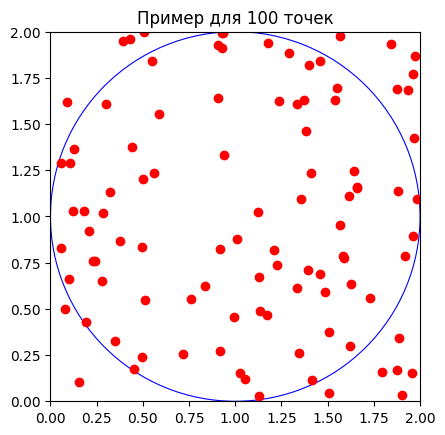

In [ ]:
fig, axes = plt.subplots()

axes.set_xlim(0, 2)
axes.set_ylim(0, 2)
axes.set_aspect(1)

axes.add_artist(plt.Circle((1, 1), radius=1, fill=False, lw=0.8, color="b"))

X = 2*np.random.rand(100)
Y = 2*np.random.rand(100)
axes.scatter(X, Y, color="r")

plt.title('Пример для 100 точек')
plt.show()


Теперь сделаем это всё в виде цикла и выведем результаты

In [ ]:
def approx_pi(N0, N1, step):
  points_count, approx = [], []

  for N in range(N0, N1+step, step):
    points = np.random.rand(N, 2)
    n = np.sum(points[:, 0]**2 + points[:, 1]**2 <= 1)  # сколько точек в окружности
    points_count.append(N)
    approx.append(4*n/N)

  return points_count, approx


In [ ]:
N0 = 1000
N1 = 50000
step = 100

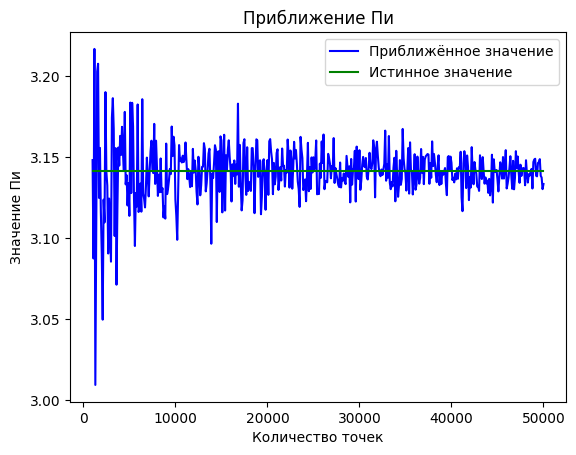

In [ ]:
fig, axes = plt.subplots()

X, Y = approx_pi(N0, N1, step)

axes.plot(X, Y, color="b", label="Приближённое значение")
axes.plot((N0, N1), (np.pi, np.pi), color="g", label="Истинное значение")

plt.xlabel("Количество точек")
plt.ylabel("Значение Пи")
plt.legend()
plt.title('Приближение Пи')
plt.show()

## Задание 3

### Условие

Студент, в распоряжении которого есть T=10 часов времени, готовится к экзамену, на котором будет представлено N=10 различных билетов, вероятность выпадения каждого из которых одинакова. Он решает из N билетов попытаться выучить n (0 ⩽ n ⩽ N), при этом затратив на изучение каждого билета равное количество времени, а именно T/n. Функция обучаемости F(t) возвращает вероятность выучить билет, потратив на его изучение t часов (t ⩾ 0, t ∈ R), является строго монотонно возрастающей и удовлетворяет условиям F(0)=0, F(+∞)=1, 0 ⩽ F(t) < 1. Подобрать (придумать) функцию F(t), удовлетворяющую условиям F(1)=0.33, F(10)=0.95, и подобрать на её основе оптимальное значение n, с точки зрения максимизации вероятности успешной сдачи экзамена.

### Решение

Каким образом подбиралась функция F(t) показано на фотографиях задания 3 в папке ProbT_Pilipenko_Photos, ссылка была скинута вместе с ссылкой на этот файл. Здесь же я покажу, как подбирал оптимальное n

In [ ]:
def F(t):
  _first = np.log(0.05) / np.log(0.67)
  _second = np.log(_first) / np.log(10)
  _third = t ** _second
  _fourth = 0.67 ** _third

  return 1 - _fourth

In [ ]:
N = 10
T = 10

max_n = 0
max_P = 0

for n in range(1, N+1):
  P = n/N * F(T/n)

  if P >= max_P:
    max_P = P
    max_n = n

print("Оптимальное n =", max_n)

Оптимальное n = 10


## Задание 4

### Условие

 Реализовать на языке программирования Python функцию, которая будет численно находить значение функции Лапласа с заданным значением точности (под точностью можно подразумевать отличие найденного значения от табличного).

### Решение

In [ ]:
def laplace(x):  # подынтегральная функция
  return np.exp(-0.5 * x**2) / np.sqrt(2*np.pi)

Решаем через формулу Симпсона (т.к. у неё хорошая точность)

N - количество разбиений отрезка [a, b]

In [ ]:
def simpson_method(f, a, b, n):
  h = (b - a)/n  # шаг
  integ = f(a) + f(b)  # изначальное значение интеграла

  for i in range(1, n):  # начинаем с 1, т.к. 0 - это точка a
    integ += f(a + i*h) * 2**(i % 2 + 1)  # при чёт 2*f(x), при неч 4*f(x)

  return integ * h/3  # в конце умножаем на h/3

Погрешность этого метода оценивается как:

$$
E ≤ \frac{b-a}{2880} h^4 max_{x∈[a,b]}|f^{(4)}(x)|
$$

Через desmos я посмотрел значение 4 производной и получилось, что её максимум равен 1.19683 в точке 0. Можно округлить и тогда максимальное значение равно 1.2

Т.к. $h=\frac{b-a}{n}$ то:

$$
E ≤ 1.2\frac{(b-a)^5}{2880n^4}
$$

и следовательно для заданной погрешности количество разбиений определяется как

$$
n = \sqrt[4]{1.2\frac{(b-a)^5}{2880E}}
$$

Для сравнения я взял значения из [этой таблицы](https://studfile.net/html/35/35fb/35fb011eb70105eb6523532ac715d5a153f736c18faad97da973e02d6d6ca913/htmlconvd-YU1MCs_html_19ace8a948351913.jpg)

В таблице значения считаются до 4 знака после запятой

Т.к. погрешность считается как половина последнего разряда, то для точности в 4 знака после запятой, значение ошибки должно быть не больше, чем 5*10^-5 (я взял просто 10^-5)

In [ ]:
a, b = 0, 2.5
precision = 4  # до скольки знаков после запятой считать

In [ ]:
error = 10**-(precision+1)
n = int(np.ceil((1.2*(b-a)**5/(2880*error))**(1/4)))

In [ ]:
table_val = 0.4938
my_val = np.round(simpson_method(laplace, a, b, n), precision)

print("Табличное значение:", table_val)
print("Моё значение:", my_val)

Табличное значение: 0.4938
Моё значение: 0.4938


## Задание 5

### Условие

1. Придумать свою случайную величину со значениями от 0 до 10 с помощью задания ее функции плотности вероятности (не использовать нормальное распределение). В блокноте Google Colab визуализировать ее
2. Визуализировать в Google Colab ее функц распределения
3. Найти чему равна вероятность того, что эта случайная величина будет принимать значения от 2 до 4

### Решение

$$
X ∈ (0, 10)
$$

Возьмём такую плотность распределения:

$$
f_X(u) = \frac{e-1}{10+u(e-1)}, u ∈ (0, 10)
$$

Функция распределния равна:

$$
F_X(t) = \int^{t}_{-\infty}{\frac{e-1}{10+u(e-1)}du}
$$

$$
F_X(t) = \int^{t}_{0}{\frac{e-1}{10+u(e-1)}du}
$$

$$
F_X(t) = {ln(10+u(e-1))|}_0^t
$$

$$
F_X(t) = ln(10+t(e-1)) - ln10
$$

Не совсем понял, что значит "визуализировать её" - имеется ввиду плотность или случайную величину? Сделал и то, и то

Для генерации случайной величины X_0, сначала найдём следующее:

$$
F_X(X_0) = a_0
$$

где $a_0 ∈ U(0, 1)$, т.е. $a_0$ распределяется равномерно

Тогда:

$$
X_0 = F_X^{-1}(a_0)
$$

И в нашем случае это равно:

$$
X_0 = 10\frac{e^{a_0}-1}{e-1}
$$

In [ ]:
def pdf(x):
  return (np.exp(1) - 1) / (10 + x * (np.exp(1) - 1))

In [ ]:
def cdf(x):
  return np.log(10 + x*(np.exp(1) - 1)) - np.log(10)

In [ ]:
def generate_X(n):
  a = np.random.uniform(0.0, 1.0, n)
  return 10 * (np.exp(a) - 1) / (np.exp(1) - 1)

In [ ]:
n = 10000

In [ ]:
X = generate_X(n)

fig = go.Figure()

fig.add_trace(go.Histogram(x=X, histnorm="probability density", xbins={"start":0.0, "end":10.0}, name="Сгенерированные значения"))

X1 = np.linspace(0, 10, n)

fig.add_trace(go.Scatter(x=X1, y=pdf(X1), mode="lines", name="Теоретическая плотность"))

fig.update_layout(title="Генерация случайной величины X", xaxis_title="X", yaxis_title="Плотность", bargap=0.01)

fig.show()

In [ ]:
fig = go.Figure()

X1 = np.linspace(0, 10, n)

fig.add_trace(go.Scatter(x=X1, y=cdf(X1), mode="lines"))

fig.update_layout(title="Функция распределения X", xaxis_title="X", yaxis_title="Распределение")

fig.show()

In [ ]:
a, b = 2, 4
print(f"Вероятность, что случайная величина принимает значение от {a} до {b} равна {cdf(b)-cdf(a)}")

Вероятность, что случайная величина принимает значение от 2 до 4 равна 0.22774263449123788


## Задание 6

### Условие

Полагая, что рост мужчин определенной возрастной группы есть нормально распределенная случайная величинах X с параметрами а = 173 и σ2 = 36. Построить графики плотности распределения вероятности и функции распределения вероятности величины X и написать их аналитический вид. Определить доли костюмов 4-го роста (176— 182 см) и 3-го роста (170—176 см), которые нужно предусмотреть в общем объеме производства для данной возрастной группы.

### Решение

Аналитически плотность нормального распределения выглядит так:

$$
f(x) = \frac{1}{\sqrt{2\pi}σ}e^{-\frac{(x-a)^2}{2σ^2}}
$$

Функция распределения вероятности выглядит следующим образом:

$$
Φ(x) = \frac{1}{\sqrt{2\pi}σ}\int_{-\infty}^x{e^{-\frac{(t-a)^2}{2σ^2}}dt}
$$

Для случая $a=173$ и $σ^2=36$ формулы будут соответственно такими:

$$
f(x) = \frac{1}{6\sqrt{2\pi}}e^{-\frac{(x-173)^2}{72}}
$$

$$
Φ(x) = \frac{1}{6\sqrt{2\pi}}\int_{-\infty}^x{e^{-\frac{(t-173)^2}{72}}dt}
$$

In [ ]:
a = 173
s = 6
n = 1000

In [ ]:
X = np.linspace(a-s**2, a+s**2, n)

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=X, y=norm.pdf(X, a, s), mode="lines"))

fig.update_layout(title="Функция плотности", xaxis_title="x", yaxis_title="y")

fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=X, y=norm.cdf(X, a, s), mode="lines"))

fig.update_layout(title="Функция распределения", xaxis_title="x", yaxis_title="y")

fig.show()

In [ ]:
x1, x2 = 176, 182
y1, y2 = 170, 176
print(f"Доля костюмов размера {x1}-{x2} см равна {norm.cdf(x2, a, s)-norm.cdf(x1, a, s)}")
print(f"Доля костюмов размера {y1}-{y2} см равна {norm.cdf(y2, a, s)-norm.cdf(y1, a, s)}")

Доля костюмов размера 176-182 см равна 0.2417303374571288
Доля костюмов размера 170-176 см равна 0.38292492254802624


## Задание 7

### Условие

Построить поверхность двумерной случайной величины Z=(X,Y), где случайные величины X и Y распределены по нормальному закону с математическими ожиданиями и дисперсиями: M(X)=1, M(Y)=1, D(X)=2, D(Y)=2. На том же графике построить кривую и поверхность, соответствующие условным случайным величинам X | X=Y и Z | X<Y. Использовать библиотеку plotly.

### Решение

Судя по условию, величины X и Y независимы, следовательно:

$$
f_Z(x, y) = f_X(x)f_Y(y)
$$

Чтобы построить плотность величины Z | X<Y воспользуемся формулой:

$$
f_{Z|X<Y}(x, y) = \frac{f_Z(x, y)}{P(X<Y)}, x<y
$$

Т.к. X и Y независимы и распределены одинаково, то:

$$
P(X<Y) = \frac{1}{2}
$$

и

$$
f_{Z|X<Y}(x, y) = 2f_Z(x, y), x<y
$$

In [ ]:
MX = 1
MY = 1
DX = 2
DY = 2

dims = 500

xmin = MX - 3*DX
xmax = MX + 3*DX
ymin = MY - 3*DY
ymax = MY + 3*DY

In [ ]:
x = np.linspace(xmin, xmax, dims)
y = np.linspace(ymin, ymax, dims)

X, Y = np.meshgrid(x, y)

Для случайной величины Z=(X,Y):

In [ ]:
Z = norm.pdf(X, MX, DX) * norm.pdf(Y, MY, DY)

Для величины X | X=Y:

In [ ]:
Z1 = norm.pdf(x, MX, DX) * norm.pdf(x, MY, DY)

Для величины Z | X<Y:

In [ ]:
Z2 = 2*Z * (X<Y)

In [ ]:
fig = go.Figure()

fig.add_trace(go.Surface(x=X, y=Y, z=Z, name="Z=(X,Y)", showscale=False))
fig.add_trace(go.Scatter3d(x=x, y=x, z=Z1, mode="lines", name="Z | X=Y", line={"color": "green", "width": 8}))
fig.add_trace(go.Surface(x=X, y=Y, z=Z2, name="X | X<Y", opacity=0.5, showscale=False))

fig.update_layout(title="Плотность Z=(X,Y)", scene={"xaxis_title": "X", "yaxis_title": "Y", "zaxis_title": "f(X,Y)"})

fig.show()

## Задание 8

### Условие

Построить вариационный ряд, гистограмму, кумуляту для https://docs.google.com/spreadsheets/d/1xuXdTzVdA_zY5QL5GKYrE73KjEVIKiVSkw3mQW2daOI/edit?usp=sharing

### Решение

Скачаем таблицу в формате CSV и загрузим в DataFrame

In [ ]:
!wget -O bodyfat.csv "https://docs.google.com/spreadsheets/d/1xuXdTzVdA_zY5QL5GKYrE73KjEVIKiVSkw3mQW2daOI/export?format=csv" -q

In [ ]:
fat_df = pd.read_csv("bodyfat.csv")
fat_df.head(10)

,BodyFat,Original,Sex,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist
0,12.3,Y,M,23,69.97,1.72,36.2,93.1,85.2,94.5,59.0,37.3,21.9,32.0,27.4,17.1
1,6.1,Y,M,22,78.59,1.84,38.5,93.6,83.0,98.7,58.7,37.3,23.4,30.5,28.9,18.2
2,25.3,Y,M,22,69.85,1.68,34.0,95.8,87.9,99.2,59.6,38.9,24.0,28.8,25.2,16.6
3,10.4,Y,M,26,83.80,1.84,37.4,101.8,86.4,101.2,60.1,37.3,22.8,32.4,29.4,18.2
4,28.7,Y,M,24,83.58,1.81,34.4,97.3,100.0,101.9,63.2,42.2,24.0,32.2,27.7,17.7
5,20.9,Y,M,24,95.37,1.90,39.0,104.5,94.4,107.8,66.0,42.0,25.6,35.7,30.6,18.8
6,19.2,Y,M,26,82.10,1.77,36.4,105.1,90.7,100.3,58.4,38.3,22.9,31.9,27.8,17.7
7,12.4,Y,M,25,79.83,1.84,37.8,99.6,88.5,97.1,60.0,39.4,23.2,30.5,29.0,18.8
8,4.1,Y,M,25,86.64,1.88,38.1,100.9,82.5,99.9,62.9,38.3,23.8,35.9,31.1,18.2
9,11.7,Y,M,23,89.93,1.87,42.1,99.6,88.6,104.1,63.1,41.7,25.0,35.6,30.0,19.2


Число интеравалов можно найти через формулу Стерджеса:

$$
m = 1 + 3.3221 lg(n)
$$

и величину интервала:

$$
k = \frac{x_{max}-x_{min}}{m}
$$

In [ ]:
row_count = fat_df.shape[0]
maxfat = fat_df["BodyFat"].max()
minfat = fat_df["BodyFat"].min()

interval_count = int(np.round(1 + 3.3221 * np.log(row_count) / np.log(10)))
interval_size = (maxfat - minfat) / interval_count

print(f"rows: {row_count}\nmax: {maxfat}\nmin: {minfat}\ninterval count: {interval_count}\ninterval size: {interval_size}")

rows: 436
max: 47.5
min: 0.0
interval count: 10
interval size: 4.75


Гистограмму (а заодно и частоты) легко найти через np.histogram()

In [ ]:
intervals = [minfat + interval_size*i for i in range(interval_count+1)]
hist_freq, hist_ints = np.histogram(fat_df["BodyFat"], bins=intervals)
print(hist_freq)
print(hist_ints)

[  8  30  58  87 113  83  41  12   3   1]
[ 0.    4.75  9.5  14.25 19.   23.75 28.5  33.25 38.   42.75 47.5 ]


P.S. В целом, можно было и не считать самому интервалы, т.к. numpy сам может это сделать, но для наглядности я решил всё же их добавить

In [ ]:
hist_freq_automatic, hist_ints_automatic = np.histogram(fat_df["BodyFat"])  # без ручного подсчёта интервалов
print(hist_freq_automatic)
print(hist_ints_automatic)

[  8  30  58  87 113  83  41  12   3   1]
[ 0.    4.75  9.5  14.25 19.   23.75 28.5  33.25 38.   42.75 47.5 ]


Теперь находим остальные параметры вариационного ряда

In [ ]:
var_prob = hist_freq / np.sum(hist_freq)

var_series = {"Интервал": [f"{hist_ints[i]} -- {hist_ints[i+1]}" for i in range(interval_count)],
              "Частота": hist_freq,
              "Частость": var_prob,
              "Накопленная частота": np.cumsum(hist_freq),
              "Накопленная частость": np.cumsum(var_prob)}

Вывод вариационного ряда в таблицу

In [ ]:
var_df = pd.DataFrame(var_series)
var_df.head(interval_count)

,Интервал,Частота,Частость,Накопленная частота,Накопленная частость
0,0.0 -- 4.75,8,0.018349,8,0.018349
1,4.75 -- 9.5,30,0.068807,38,0.087156
2,9.5 -- 14.25,58,0.133028,96,0.220183
3,14.25 -- 19.0,87,0.199541,183,0.419725
4,19.0 -- 23.75,113,0.259174,296,0.678899
5,23.75 -- 28.5,83,0.190367,379,0.869266
6,28.5 -- 33.25,41,0.094037,420,0.963303
7,33.25 -- 38.0,12,0.027523,432,0.990826
8,38.0 -- 42.75,3,0.006881,435,0.997706
9,42.75 -- 47.5,1,0.002294,436,1.000000


Теперь выводим графики

In [ ]:
fig = go.Figure()

fig.add_trace(go.Bar(x=var_series["Интервал"], y=var_series["Частота"]))

fig.update_layout(title="Гистограмма вариационного ряда", xaxis_title="Интервал", yaxis_title="Частота")

fig.show()

In [ ]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=var_series["Интервал"], y=var_series["Накопленная частота"], mode="lines"))

fig.update_layout(title="Кумулята вариационного ряда", xaxis_title="Интервал", yaxis_title="Накопленная частота")

fig.show()

## Задание 9

### Условие

Для pdf, которое лучшим образом описывает статистику задания №8, найти: математическое ожидание, дисперсию, моду, медиану, квантили, начальные и центральные моменты до 4,  коэффициент асимметрии, эксцесс.

### Решение

Функцию плотности можно подобрать, используя ядерную оценку плотности. Для этого воспользуемся формулой:

$$
f_h(x) = \frac{1}{nh}\sum_{i=1}^nK(\frac{x-x_i}{h})
$$

где:
* $x_i$ - независимые одинаково распределённые величины
* $n$ - количество этих величин
* $h$ - сглаживающий параметр (ширина полосы), $h>0$
* $K$ - ядро, т.е. некая неотрицательная функция, а также симметричная и $\int_{-\infty}^{\infty}K(u)du=1$

In [ ]:
class KDE:  # kernel density estimation
  def __init__(self, kernel, h):
    self._h = h
    self._kernel = kernel

  def fit(self, X: np.ndarray):
    self._X = np.copy(X)
    self._n = self._X.shape[0]

  def predict(self, X: np.ndarray) -> np.ndarray:
    k_values = np.zeros(self._n, dtype=np.float64)
    pred_values = np.zeros(X.shape, dtype=np.float64)

    for i in range(pred_values.shape[0]):
      for j in range(self._n):
        u = (X[i] -self._X[j]) / self._h
        pred_values[i] += self._kernel(u)

      pred_values[i] /= (self._h * self._n)

    return pred_values

В качестве ядра я думаю лучше всего взять функию Гаусса:

$$
K(u) = \frac{1}{\sqrt{2\pi}}exp(\frac{-u^2}{2})
$$

так как распределение величины очень похоже на нормальное

In [ ]:
def kernel(x):
  return np.exp(-x**2/2) / np.sqrt(2*np.pi)

Эмпирическим путём (несколько запусков) было подобрано такое значение h:

In [ ]:
h = 2.0

In [ ]:
pdf = KDE(kernel, h)
pdf.fit(fat_df["BodyFat"])

Величина X и её плотность Y (чтобы не считать плотность по нескольку раз, найдём её сразу и будем подставлять)

In [ ]:
X = np.linspace(minfat, maxfat, 1000)
Y = pdf.predict(X)

Первые 4 начальных момента

In [ ]:
dx = (X[-1] + X[0]) / X.shape[0]
pdf_moments = [np.sum(X**i * Y * dx) for i in range(1, 5)]

for i in range(4):
  print(f"{i+1}-й начальный момент: {pdf_moments[i]}")

1-й начальный момент: 20.17720590809627
2-й начальный момент: 466.99174938372727
3-й начальный момент: 11811.831374768812
4-й начальный момент: 319894.72748913616


Мат. ожидание - это 1 начальный момент

In [ ]:
pdf_mean = pdf_moments[0]
print("Мат. ожидание:", pdf_mean)

Мат. ожидание: 20.17720590809627


Первые 4 центральных момента

In [ ]:
pdf_central_moments = [np.sum((X-pdf_mean)**i * Y * dx) for i in range(1, 5)]

for i in range(4):
  print(f"{i+1}-й центральный момент: {pdf_central_moments[i]}")

1-й центральный момент: 0.09241272412784118
2-й центральный момент: 58.00748056275669
3-й центральный момент: 10.761896204651748
4-й центральный момент: 9306.457472415874


Дисперсия - это 2 центральный момент

In [ ]:
pdf_var = pdf_central_moments[1]
print("Дисперсия:", pdf_var)

Дисперсия: 58.00748056275669


Мода - это значение x, где pdf(x) достигает экстремума

In [ ]:
index_max = np.argmax(Y)
pdf_mode = X[index_max]
print("Мода:", pdf_mode)

Мода: 21.396396396396394


Функция для вычисления процентиля

In [ ]:
def percentile(X, Y, q):
  F = 0  # cdf
  N = X.shape[0]

  dx = (X[-1] - X[0]) / N

  for i in range(N):
    F += Y[i] * dx

    if F >= q/100:
      return X[i]

  return X[-1]

Медиана - 50 процентиль

In [ ]:
pdf_median = percentile(X, Y, 50)
print("Медиана:", pdf_median)

Медиана: 20.54054054054054


Квантили (25 процентиль и 75 процентиль)

In [ ]:
pdf_q25 = percentile(X, Y, 25)
pdf_q75 = percentile(X, Y, 75)
print(f"Q25: {pdf_q25}\nQ75: {pdf_q75}")

Q25: 15.025025025025023
Q75: 25.58058058058058


Коэффициент асимметрии равен:

$$
A_s=\frac{\mu_3}{\sigma^3}
$$

где:
* $\mu_3$ - третий центральный момент
* $\sigma$ - стандартное отклонение

In [ ]:
pdf_std = np.sqrt(pdf_var)
pdf_coef_asym = pdf_central_moments[2] / (pdf_std ** 3)
print("Коэф. асимметрии:", pdf_coef_asym)

Коэф. асимметрии: 0.024359187275563826


Коэффициент эксцесса равен:

$$
\gamma_2 = \frac{\mu_4}{\sigma^4} - 3
$$

где:
* $\mu_4$ - четвёртый центральный момент
* $\sigma$ - стандартное отклонение

In [ ]:
pdf_coef_exc = pdf_central_moments[3] / (pdf_std ** 4) - 3
print("Коэф. эксцесса:", pdf_coef_exc)

Коэф. эксцесса: -0.23422790369648405


График плотности величины

P.S. plotly при построении гистограммы для всех стобцов берёт значения [a, b), даже для последнего, из-за чего на графике и получился справа такой пробел. При этом numpy правильно обрабатывает конечный столбец, т.е. включает точку b

In [ ]:
fig = go.Figure()

ymax = np.max(Y)

fig.add_trace(go.Histogram(x=fat_df["BodyFat"], xbins={"start": minfat, "size": interval_size}, histnorm="probability density", name="Исходная статистика"))

fig.add_trace(go.Scatter(x=X, y=Y, mode="lines", name="Подобранная функция плотности"))

fig.add_trace(go.Scatter(x=[pdf_mean, pdf_mean], y=[0.0, ymax], mode="lines", name="Мат. ожидание"))
fig.add_trace(go.Scatter(x=[pdf_mode, pdf_mode], y=[0.0, ymax], mode="lines", name="Мода"))
fig.add_trace(go.Scatter(x=[pdf_median, pdf_median], y=[0.0, ymax], mode="lines", name="Медиана"))

fig.update_layout(title="Плотность величины", xaxis_title="X", yaxis_title="f(X)", bargap=0.05)

fig.show()